In [1]:
from Bio import SeqIO

In [3]:
file_path = "/Users/owner/Desktop/DNA seq analyzer/data/raw/sequence.fasta"
record = SeqIO.read(file_path, "fasta")

In [4]:
print(record.id)
print(record.description)
print(len(record.seq))

OR327029.1
OR327029.1 Homo sapiens voucher BuKa3C mitochondrion, complete genome
16567


In [5]:
sequence = record.seq

print("A:", sequence.count("A"))
print("T:", sequence.count("T"))
print("C:", sequence.count("C"))
print("G:", sequence.count("G"))

A: 5115
T: 4097
C: 5178
G: 2177


In [6]:
gc_content = (sequence.count("G") + sequence.count("C")) / len(sequence) * 100

print(f"GC content: {gc_content:.2f}%")

GC content: 44.40%


In [7]:
def calculate_gc(seq):
    gc = seq.count("G") + seq.count("C")
    return (gc / len(seq)) * 100

In [8]:
calculate_gc(sequence)

44.395485000301804

In [9]:
gc_result = calculate_gc(sequence)

print(f"GC content of {record.id}: {gc_result:.2f}%")

GC content of OR327029.1: 44.40%


In [10]:
for base in ["A", "T", "C", "G"]:
    percentage = sequence.count(base) / len(sequence) * 100
    print(f"{base}: {percentage:.2f}%")

A: 30.87%
T: 24.73%
C: 31.25%
G: 13.14%


In [11]:
total_percentage = sum(
    sequence.count(base) / len(sequence) * 100
    for base in ["A", "T", "C", "G"]
)

print(f"Total: {total_percentage:.2f}%")


Total: 100.00%


In [12]:
set(sequence)

{'A', 'C', 'G', 'T'}

In [13]:
import matplotlib.pyplot as plt

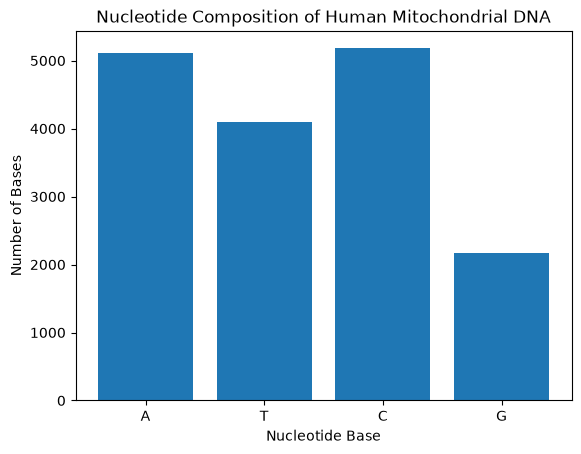

In [14]:
bases = ["A", "T", "C", "G"]
counts = [sequence.count(base) for base in bases]

plt.bar(bases, counts)

plt.title("Nucleotide Composition of Human Mitochondrial DNA")
plt.xlabel("Nucleotide Base")
plt.ylabel("Number of Bases")

plt.show()

In [15]:
cox1_sequence = record.seq[5901:7443]

print("COX1 length:", len(cox1_sequence))

COX1 length: 1542


In [16]:
for base in ["A", "T", "C", "G"]:
    count = cox1_sequence.count(base)
    percentage = count / len(cox1_sequence) * 100
    print(f"{base}: {count} ({percentage:.2f}%)")

A: 419 (27.17%)
T: 411 (26.65%)
C: 462 (29.96%)
G: 250 (16.21%)


In [17]:
cox1_gc = calculate_gc(cox1_sequence)

print(f"COX1 GC content: {cox1_gc:.2f}%")

COX1 GC content: 46.17%


In [18]:
from Bio.Seq import Seq

In [19]:
cox1_protein = cox1_sequence.translate(table=2)

print(cox1_protein)

MFADRWLFSTNHKDIGTLYLLFGAWAGVLGTALSLLIRAELGQPGNLLGNDHIYNVIVTAHAFVMIFFMVMPIMIGGFGNWLVPLMIGAPDMAFPRMNNMSFWLLPPSLLLLLASAMVEAGAGTGWTVYPPLAGNYSHPGASVDLTIFSLHLAGVSSILGAINFITTIINMKPPAMTQYQTPLFVWSVLITAVLLLLSLPVLAAGITMLLTDRNLNTTFFDPAGGGDPILYQHLFWFFGHPEVYILILPGFGMISHIVTYYSGKKEPFGYMGMVWAMMSIGFLGFIVWAHHMFTVGMDVDTRAYFTSATMIIAIPTGVKVFSWLATLHGSNMKWSAAVLWALGFIFLFTVGGLTGIVLANSSLDIVLHDTYYVVAHFHYVLSMGAVFAIMGGFIHWFPLFSGYTLDQTYAKIHFTIMFIGVNLTFFPQHFLGLSGMPRRYSDYPDAYTTWNILSSVGSFISLTAVMLMIFMIWEAFASKRKVLMVEEPSMNLEWLYGCPPPYHTFEEPVYMKS*


In [20]:
print("Protein length:", len(cox1_protein.rstrip("*")))

Protein length: 513


In [21]:
print("Protein ID: WND63996.1")
print("Translated amino acids:", len(cox1_protein.rstrip("*")))
print("Starts with:", cox1_protein[:10])
print("Ends with:", cox1_protein[-10:])
print("Has terminal stop:", str(cox1_protein).endswith("*"))

Protein ID: WND63996.1
Translated amino acids: 513
Starts with: MFADRWLFST
Ends with: FEEPVYMKS*
Has terminal stop: True


In [22]:
from pathlib import Path

print([file.name for file in Path(file_path).parent.iterdir()])

['.DS_Store', 'sequence.fasta', 'sequence.gb']


In [23]:
genbank_record = SeqIO.read(
    file_path.replace("sequence.fasta", "sequence.gb"),
    "genbank"
)

print(genbank_record.id)

OR327029.1


In [24]:
for feature in genbank_record.features:
    if feature.type == "CDS" and feature.qualifiers.get("gene") == ["COX1"]:
        print(feature.qualifiers["protein_id"])
        print(feature.qualifiers["product"])

['WND63996.1']
['cytochrome oxidase subunit 1']


In [25]:
for feature in genbank_record.features:
    if feature.type == "CDS" and feature.qualifiers.get("gene") == ["COX1"]:
        reference_protein = feature.qualifiers["translation"][0]

In [26]:
translated = str(cox1_protein).rstrip("*")

print("Our protein length:", len(translated))
print("NCBI reference length:", len(reference_protein))
print("Exact match:", translated == reference_protein)

Our protein length: 513
NCBI reference length: 513
Exact match: True


In [27]:
codons = [
    str(cox1_sequence[i:i+3])
    for i in range(0, len(cox1_sequence), 3)
]

print(codons[:10])

['ATG', 'TTC', 'GCC', 'GAC', 'CGT', 'TGA', 'CTA', 'TTC', 'TCT', 'ACA']


In [28]:
from collections import Counter

In [29]:
codon_counts = Counter(codons)

print(codon_counts.most_common(10))

[('CTA', 33), ('TTC', 29), ('ATC', 26), ('ATA', 25), ('GGA', 19), ('TAC', 18), ('CCC', 18), ('GGC', 17), ('GTA', 17), ('TGA', 16)]


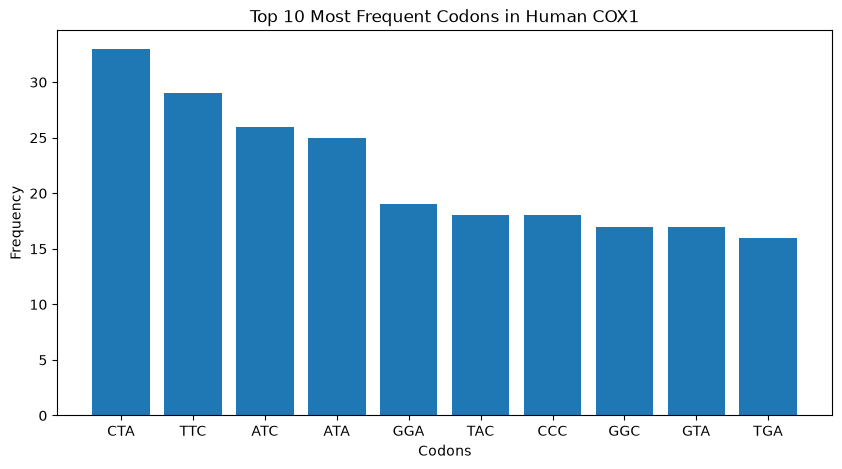

In [30]:
top_codons = codon_counts.most_common(10)

labels = [item[0] for item in top_codons]
frequencies = [item[1] for item in top_codons]

plt.figure(figsize=(10, 5))
plt.bar(labels, frequencies)

plt.title("Top 10 Most Frequent Codons in Human COX1")
plt.xlabel("Codons")
plt.ylabel("Frequency")

plt.show()

In [31]:
print("Total codons:", len(codons))
print("Unique codons:", len(codon_counts))

Total codons: 514
Unique codons: 55


In [32]:
print("Last codon:", codons[-1])
print("Last translated character:", str(cox1_protein)[-1])

Last codon: AGA
Last translated character: *


In [33]:
from pathlib import Path

processed_dir = Path(file_path).parent.parent / "processed"
processed_dir.mkdir(exist_ok=True)

print("Processed folder:", processed_dir)


Processed folder: /Users/owner/Desktop/DNA seq analyzer/data/processed


In [34]:
from Bio.SeqRecord import SeqRecord

cox1_record = SeqRecord(
    cox1_sequence,
    id="OR327029.1_COX1",
    description="Homo sapiens mitochondrial cytochrome c oxidase subunit 1"
)

In [35]:
SeqIO.write(
    cox1_record,
    processed_dir / "COX1.fasta",
    "fasta"
)

1

In [36]:
saved_cox1 = SeqIO.read(processed_dir / "COX1.fasta", "fasta")

print("ID:", saved_cox1.id)
print("Length:", len(saved_cox1.seq))
print("Sequence matches:", saved_cox1.seq == cox1_sequence)

ID: OR327029.1_COX1
Length: 1542
Sequence matches: True


In [37]:
import pandas as pd

In [38]:
results = pd.DataFrame({
    "Measurement": [
        "Genome length",
        "Genome GC content",
        "COX1 length",
        "COX1 GC content",
        "COX1 protein length",
        "Total codons",
        "Unique codons",
        "NCBI protein match"
    ],
    "Value": [
        len(sequence),
        round(gc_result, 2),
        len(cox1_sequence),
        round(cox1_gc, 2),
        len(translated),
        len(codons),
        len(codon_counts),
        translated == reference_protein
    ]
})

results

,Measurement,Value
0,Genome length,16567
1,Genome GC content,44.4
2,COX1 length,1542
3,COX1 GC content,46.17
4,COX1 protein length,513
5,Total codons,514
6,Unique codons,55
7,NCBI protein match,True


In [39]:
results.to_csv(processed_dir / "COX1_analysis_results.csv", index=False)

In [40]:
print((processed_dir / "COX1_analysis_results.csv").exists())

True


In [41]:
project_dir = Path(file_path).parent.parent.parent

results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

print(project_dir)

/Users/owner/Desktop/DNA seq analyzer


In [42]:
readme_path = project_dir / "README.md"

print(readme_path)

/Users/owner/Desktop/DNA seq analyzer/README.md


In [43]:
readme_path.write_text("""
# DNA Sequence Analyzer

## 1. Project Objective

Analyze a human mitochondrial DNA sequence using Python and
Biopython. Investigate nucleotide composition, GC content,
and the COX1 gene. Translate COX1 into its protein sequence
and validate the result against the NCBI reference annotation.

## 2. Dataset

- Database: NCBI Nucleotide
- Accession: OR327029.1
- Organism: Homo sapiens
- Sample: Voucher BuKa3C
- Sequence type: Complete mitochondrial genome
- Genome length: 16,567 bp
- Gene analyzed: COX1

The dataset represents an ancient human specimen.

## 3. Tools and Libraries

- Python
- Biopython
- Pandas
- Matplotlib
- JupyterLab

## 4. Methodology

1. Imported the mitochondrial genome in FASTA format.
2. Counted A, T, C and G nucleotides.
3. Calculated genome GC content.
4. Visualized nucleotide composition.
5. Extracted COX1 using GenBank coordinates.
6. Calculated COX1 nucleotide composition and GC content.
7. Translated COX1 using vertebrate mitochondrial genetic code (table 2).
8. Analyzed codon frequencies.
9. Compared the translated protein with the NCBI reference.
10. Exported the extracted gene and analysis results.

## 5. Results

| Measurement | Result |
|---|---:|
| Genome length | 16,567 bp |
| Genome GC content | 44.40% |
| COX1 length | 1,542 bp |
| COX1 GC content | 46.17% |
| COX1 protein length | 513 amino acids |
| Total codons | 514 |
| Unique codons | 55 |
| NCBI protein match | True |

## 6. Validation

The translated COX1 protein was compared with the
NCBI annotated protein WND63996.1.

Both sequences contained 513 amino acids and matched
exactly.

## 7. Scientific Reference

Cock PJA et al. (2009).
Biopython: freely available Python tools for computational
molecular biology and bioinformatics.
Bioinformatics.

https://doi.org/10.1093/bioinformatics/btp163

## 8. Data Source

NCBI Nucleotide:
https://www.ncbi.nlm.nih.gov/nuccore/OR327029.1
""")

print("README created:", readme_path.exists())

README created: True


In [44]:
for path in sorted(project_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(project_dir))

.DS_Store
README.md
data/.DS_Store
data/processed/COX1.fasta
data/processed/COX1_analysis_results.csv
data/raw/.DS_Store
data/raw/sequence.fasta
data/raw/sequence.gb
